# S³ semantic-axis smoke test

This exploratory test fits Turftopic S³ to the existing semantic passages using the saved BGE-M3 vectors. Passage embeddings are loaded from disk and passed through `embeddings=`; they are not recomputed. The matching local BGE model is used only for vocabulary-term embeddings.

This fit uses 5 components and seed 42. Scores are signed ICA coordinates, not calibrated probabilities or BERTopic topics. Review the displayed positive/negative evidence before interpreting an axis. Original BERTopic assignments are not changed.

Run from the repository root with `uv run --group topic-analysis jupyter lab`.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer
from turftopic import SemanticSignalSeparation

project_root = Path.cwd().resolve()
if not (project_root / 'data/topic-analysis').exists():
    project_root = project_root.parent
if not (project_root / 'data/topic-analysis').exists():
    raise FileNotFoundError('Could not locate data/topic-analysis from the notebook working directory')
results = project_root / 'data/topic-analysis/results'
dataset_path = results / 'segment-dataset/all-segments.parquet'
embedding_path = results / 'jev-semantic-all/bubble-maps/segment-embeddings.npy'
embedding_manifest_path = results / 'jev-semantic-all/bubble-maps/embedding-manifest.json'
model_manifest_path = results / 'segment-dataset/manifest.json'
MODEL_ID = 'BAAI/bge-m3'
MODEL_REVISION = '5617a9f61b028005a4858fdac845db406aefb181'
N_COMPONENTS, RANDOM_STATE = 5, 42
print(f'Project: {project_root}')
print(f'Saved vectors: {embedding_path}')

ModuleNotFoundError: No module named 'sentence_transformers'

In [ ]:
wanted = ['segment_key', 'segmentation', 'passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'topic_name', 'membership_strength']
available = set(pd.read_parquet(dataset_path).columns)
all_passages = pd.read_parquet(dataset_path, columns=[c for c in wanted if c in available])
passages = all_passages.loc[all_passages.segmentation == 'semantic'].reset_index(drop=True)
embedding_manifest = json.loads(embedding_manifest_path.read_text(encoding='utf-8'))
model_info = json.loads(model_manifest_path.read_text(encoding='utf-8'))['models']['semantic']
embeddings = np.load(embedding_path, allow_pickle=False)
assert model_info['embedding_model_id'] == MODEL_ID
assert model_info['embedding_revision'] == MODEL_REVISION
assert int(model_info['embedding_dimension']) == 1024
assert passages.segment_key.tolist() == embedding_manifest['segment_keys'], 'Passage/vector order mismatch'
assert embeddings.shape == (len(passages), 1024), embeddings.shape
assert embeddings.dtype == np.float32 and np.isfinite(embeddings).all()
assert np.allclose(np.linalg.norm(embeddings, axis=1), 1.0, atol=1e-4), 'Vectors are not L2-normalized'
print(f'Validated {len(passages):,} passages × {embeddings.shape[1]} dimensions; float32, finite, L2-normalized.')
print(f"Model: {model_info['embedding_model_id']} @ {model_info['embedding_revision']}")
print(f"Original BERTopic outliers (topic -1): {(passages.topic_id == -1).sum():,}")

## Fit on the precomputed vectors

The encoder is loaded from local cache only. If that exact revision is not cached, the cell fails instead of downloading or substituting another model. Turftopic receives the corpus matrix directly via `embeddings=embeddings`.

In [ ]:
encoder = SentenceTransformer(MODEL_ID, revision=MODEL_REVISION, local_files_only=True)
s3 = SemanticSignalSeparation(n_components=N_COMPONENTS, encoder=encoder, vectorizer=CountVectorizer(max_features=500), random_state=RANDOM_STATE)
scores = s3.fit_transform(passages.text.tolist(), embeddings=embeddings)
assert scores.shape == (len(passages), N_COMPONENTS), scores.shape
assert np.isfinite(scores).all(), 'S³ scores contain non-finite values'
score_columns = [f's3_component_{i}' for i in range(N_COMPONENTS)]
scored_passages = passages.copy()
for i, column in enumerate(score_columns):
    scored_passages[column] = scores[:, i]
print(f'S³ fit passed: {len(passages):,} passages, {N_COMPONENTS} components, seed {RANDOM_STATE}.')
print('Passage vectors came from disk; no passage re-embedding was run.')

## S³ component summary and naming evidence

S³ returns continuous bipolar axes, not discrete topic assignments. The dominant-axis count below is only an exploratory tally: each passage is counted under the component with its largest absolute standardized score. It is not a cluster count or a calibrated classification. For naming, review Turftopic's high/low term lists alongside the positive/negative extreme passages below, then enter a human-reviewed bipolar label; no labels are generated automatically.

In [ ]:
score_frame = pd.DataFrame(scores, columns=score_columns)
score_std = score_frame.std(ddof=0).replace(0, 1)
score_z = (score_frame - score_frame.mean()) / score_std
dominant_component_index = np.abs(score_z.to_numpy()).argmax(axis=1)
dominant_counts = pd.Series(dominant_component_index).value_counts().reindex(range(N_COMPONENTS), fill_value=0)
positive_terms = s3.get_top_words(top_k=12, positive=True)
negative_terms = s3.get_top_words(top_k=12, positive=False)

component_stats = pd.DataFrame({
    'component_id': range(N_COMPONENTS),
    'passage_count': len(score_frame),
    'score_nan_count': score_frame.isna().sum().to_numpy(),
    'positive_score_count': score_frame.gt(0).sum().to_numpy(),
    'negative_score_count': score_frame.lt(0).sum().to_numpy(),
    'mean_score': score_frame.mean().to_numpy(),
    'score_std': score_frame.std(ddof=0).to_numpy(),
    'min_score': score_frame.min().to_numpy(),
    'max_score': score_frame.max().to_numpy(),
    'dominant_axis_passages_exploratory': dominant_counts.to_numpy(),
})
print(f'S³ passages scored: {len(score_frame):,}; missing passage texts: {passages.text.isna().sum():,}; blank passage texts: {(passages.text.notna() & passages.text.astype("string").str.strip().eq("")).sum():,}')
print('Continuous score distribution and exploratory dominant-axis counts (not topic membership)')
display(component_stats)

axis_review = pd.DataFrame({
    'component_id': range(N_COMPONENTS),
    'positive_end_terms': [', '.join(words) for words in positive_terms],
    'negative_end_terms': [', '.join(words) for words in negative_terms],
    'reviewed_bipolar_label': ['' for _ in range(N_COMPONENTS)],
    'review_notes': ['' for _ in range(N_COMPONENTS)],
})
print('Naming evidence: use both ends of each axis and verify them against the extreme passages in the next cell.')
display(axis_review)
assert int(component_stats.passage_count.iloc[0]) == len(passages)
assert int(component_stats.score_nan_count.sum()) == int(score_frame.isna().sum().sum())
assert int(component_stats.dominant_axis_passages_exploratory.sum()) == len(passages)
print(f"S3_COMPONENT_STATS_OK passages={len(passages):,}; components={N_COMPONENTS}; missing_scores={int(score_frame.isna().sum().sum())}")

## 2-D view of the S³ axes

Each panel shows the same passage map: a PCA projection of the already-saved embeddings. Color shows the signed standardized S³ score for that panel's axis; outlined points are original BERTopic outliers (`topic_id == -1`). The map is only a 2-D projection and does not define clusters or topics.

The table below gives one strongest positive and negative evidence passage per axis, alongside top terms. These are evidence for human review, not automatic topic names.

In [ ]:
projection = PCA(n_components=2, svd_solver='randomized', random_state=RANDOM_STATE).fit_transform(embeddings)
assert projection.shape == (len(passages), 2) and np.isfinite(projection).all()
projection_variance = PCA(n_components=2, svd_solver='randomized', random_state=RANDOM_STATE).fit(embeddings).explained_variance_ratio_.sum()
outlier_mask = passages.topic_id.eq(-1).to_numpy()
ncols = min(5, N_COMPONENTS)
nrows = (N_COMPONENTS + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), sharex=True, sharey=True, constrained_layout=True)
axes = np.asarray(axes).reshape(-1)
for component_id, ax in enumerate(axes):
    if component_id >= N_COMPONENTS:
        ax.set_visible(False)
        continue
    values = score_z.iloc[:, component_id].to_numpy()
    ax.scatter(projection[:, 0], projection[:, 1], c=values, cmap='RdBu_r', vmin=-3, vmax=3, s=9, alpha=0.7, linewidths=0, rasterized=True)
    ax.scatter(projection[outlier_mask, 0], projection[outlier_mask, 1], facecolors='none', edgecolors='#222222', s=16, linewidths=0.45, alpha=0.7, rasterized=True)
    ax.set_title(f'Axis {component_id}')
    ax.set_xticks([]); ax.set_yticks([])
fig.supxlabel('PCA dimension 1'); fig.supylabel('PCA dimension 2')
fig.suptitle(f'S³ signed scores across the same 2-D embedding projection (PCA variance: {projection_variance:.1%})')
fig.colorbar(axes.flat[0].collections[0], ax=axes.ravel().tolist(), label='Standardized S³ score (colors clipped at ±3 SD)', shrink=0.78)
plt.show()

assert len(score_z.columns) == N_COMPONENTS
assert len(projection) == len(passages) == len(scored_passages)
assert int(outlier_mask.sum()) == int((passages.topic_id == -1).sum())
print(f'2-D projection uses the saved {embeddings.shape[1]}-D vectors for {len(passages):,} passages; BERTopic outliers outlined: {outlier_mask.sum():,}.')

table_rows = []
for component_id, score_column in enumerate(score_columns):
    positive = scored_passages[score_column].idxmax()
    negative = scored_passages[score_column].idxmin()
    pos = scored_passages.loc[positive]
    neg = scored_passages.loc[negative]
    table_rows.append({
        'axis': component_id,
        'positive terms': ', '.join(positive_terms[component_id][:8]),
        'positive passage': f"{pos.get('episode_id', '')} | {pos.get('title', '')} | {pos.get('start_seconds', '')}–{pos.get('end_seconds', '')}s | BERTopic {pos.get('topic_id', '')} | score {pos[score_column]:.3f} | {pos.get('text', '')}",
        'negative terms': ', '.join(negative_terms[component_id][:8]),
        'negative passage': f"{neg.get('episode_id', '')} | {neg.get('title', '')} | {neg.get('start_seconds', '')}–{neg.get('end_seconds', '')}s | BERTopic {neg.get('topic_id', '')} | score {neg[score_column]:.3f} | {neg.get('text', '')}",
    })
axis_evidence_table = pd.DataFrame(table_rows)
assert len(axis_evidence_table) == N_COMPONENTS
print('Strongest passage at each end of each component; use both poles and review the linked transcript/audio before naming an axis.')
display(axis_evidence_table)

In [ ]:
evidence_columns = [c for c in ['passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'membership_strength'] if c in scored_passages.columns]
for i, score_column in enumerate(score_columns):
    print(f'Component {i}: highest-scoring passages')
    display(scored_passages.nlargest(3, score_column)[evidence_columns + [score_column]].reset_index(drop=True))
    print(f'Component {i}: lowest-scoring passages')
    display(scored_passages.nsmallest(3, score_column)[evidence_columns + [score_column]].reset_index(drop=True))
outliers = scored_passages.loc[scored_passages.topic_id == -1].copy()
outlier_view = outliers[evidence_columns + score_columns].sort_values(score_columns[0], key=lambda x: x.abs(), ascending=False)
print(f'Outliers shown for additional evidence review: {len(outliers):,} total; first 12 by absolute component-0 score.')
display(outlier_view.head(12).reset_index(drop=True))

High = above the 70th percentile; Low = below the 30th percentile among topic groups, ranked separately for each axis. Exact boundaries and the middle 40% are Typical. These are relative comparisons, not probabilities.
Percentile ranks compare topic-group means independently within each S³ axis.


axis_id,dimension_name,positive_end_keywords,negative_end_keywords
0,People ↔ schooling,"inimeste, inimese, euroopa, inimest, inimesi, palun, kellel, inimene, vastu, ees, sinna, riigi","koolis, kooli, õpetaja, teen, teed, teeme, alguses, mitu, elu, mõtlema, teha, tee"
1,Europe ↔ work,"euroopa, suur, olid, olnud, ilmselt, elu, üsna, kust, tule, tõenäoliselt, olemas, of","tööle, õpetaja, koolis, töö, tööd, head, sisse, inimese, ai, hoida, it, kooli"
2,State ↔ scarcity,"riigi, riik, euroopa, it, arvan, eest, kes, oleme, ai, ega, eesti, kelle","vähem, vähe, tihti, natukene, puhul, korraks, juhul, minema, lihtne, mingisugune, hakkama, kodus"
3,AI / work ↔ children,"ai, it, aeg, tee, arust, ega, tööle, tööd, tekib, teeb, kasutada, teed","lapsed, koolis, õpetaja, riigi, kooli, riik, inimeste, olla, olema, rääkida, minema, inimesed"
4,Education ↔ money,"ai, teen, kunagi, tee, huvitav, koolis, kooli, iganes, räägi, you, meil, tea","raha, riik, riigi, hoida, vähem, palju, jääb, vähe, lapsed, tööle, olukord, euroopa"


topic_name,passage_count,high_dimensions,low_dimensions,highest_dimension,highest_mean_z,highest_axis_positive_keywords,lowest_dimension,lowest_mean_z,lowest_axis_negative_keywords,axis_0_mean_z,axis_1_mean_z,axis_2_mean_z,axis_3_mean_z,axis_4_mean_z
AI abil teksti ja heli konverteerimine,9,"State ↔ scarcity, AI / work ↔ children, Education ↔ money",—,AI / work ↔ children,1.401,"ai, it, aeg, tee, arust, ega, tööle, tööd, tekib, teeb, kasutada, teed",Europe ↔ work,-0.647,"tööle, õpetaja, koolis, töö, tööd, head, sisse, inimese, ai, hoida, it, kooli",-0.536909,-0.646625,1.320838,1.401396,0.721530
AI kasutamine töö- ja loometekstide koostamisel,7,"People ↔ schooling, State ↔ scarcity, AI / work ↔ children, Education ↔ money",—,AI / work ↔ children,1.648,"ai, it, aeg, tee, arust, ega, tööle, tööd, tekib, teeb, kasutada, teed",Europe ↔ work,-0.580,"tööle, õpetaja, koolis, töö, tööd, head, sisse, inimese, ai, hoida, it, kooli",0.553012,-0.580463,0.675553,1.648026,1.533624
AI kasutamise reeglid ja hindamine ülikoolis,16,"State ↔ scarcity, AI / work ↔ children, Education ↔ money",Europe ↔ work,Education ↔ money,1.677,"ai, teen, kunagi, tee, huvitav, koolis, kooli, iganes, räägi, you, meil, tea",Europe ↔ work,-0.816,"tööle, õpetaja, koolis, töö, tööd, head, sisse, inimese, ai, hoida, it, kooli",-0.570665,-0.815546,0.587308,1.156502,1.677401
AI muudab üksikettevõtluse lihtsamaks,6,"State ↔ scarcity, AI / work ↔ children, Education ↔ money",—,AI / work ↔ children,1.645,"ai, it, aeg, tee, arust, ega, tööle, tööd, tekib, teeb, kasutada, teed",Europe ↔ work,-0.620,"tööle, õpetaja, koolis, töö, tööd, head, sisse, inimese, ai, hoida, it, kooli",-0.111759,-0.620477,1.503803,1.644576,0.861757
AI mõju töökorraldusele ja tööturule,8,"State ↔ scarcity, AI / work ↔ children, Education ↔ money",Europe ↔ work,AI / work ↔ children,1.375,"ai, it, aeg, tee, arust, ega, tööle, tööd, tekib, teeb, kasutada, teed",Europe ↔ work,-1.361,"tööle, õpetaja, koolis, töö, tööd, head, sisse, inimese, ai, hoida, it, kooli",-0.065635,-1.361153,0.553224,1.375320,0.763005
AI odava kasutuselevõtu ja eksporti,13,"State ↔ scarcity, AI / work ↔ children, Education ↔ money",—,AI / work ↔ children,1.769,"ai, it, aeg, tee, arust, ega, tööle, tööd, tekib, teeb, kasutada, teed",Europe ↔ work,-0.302,"tööle, õpetaja, koolis, töö, tööd, head, sisse, inimese, ai, hoida, it, kooli",0.276409,-0.301893,0.974263,1.768979,0.691517
AI päringute energiakulu läbipaistvus,14,"AI / work ↔ children, Education ↔ money",—,AI / work ↔ children,2.025,"ai, it, aeg, tee, arust, ega, tööle, tööd, tekib, teeb, kasutada, teed",People ↔ schooling,-0.529,"koolis, kooli, õpetaja, teen, teed, teeme, alguses, mitu, elu, mõtlema, teha, tee",-0.529318,0.271373,0.081163,2.024694,0.523646
AI roll arstide suhtluses ja vähiravis,11,"People ↔ schooling, AI / work ↔ children, Education ↔ money",Europe ↔ work,AI / work ↔ children,1.644,"ai, it, aeg, tee, arust, ega, tööle, tööd, tekib, teeb, kasutada, teed",Europe ↔ work,-1.213,"tööle, õpetaja, koolis, töö, tööd, head, sisse, inimese, ai, hoida, it, kooli",1.362828,-1.213208,0.342942,1.644388,0.559940
AI roll elamisloa otsustes,17,"People ↔ schooling, State ↔ scarcity, AI / work ↔ children",—,AI / work ↔ children,0.682,"ai, it, aeg, tee, arust, ega, tööle, tööd, tekib, teeb, kasutada, teed",Europe ↔ work,-0.304,"tööle, õpetaja, koolis, töö, tööd, head, sisse, inimese, ai, hoida, it, kooli",0.549102,-0.304090,0.533976,0.681601,0.324641
AI-agentide vastutus ja kontroll,10,"People ↔ schooling, State ↔ scarcity, AI / work ↔ children, Education ↔ money",—,AI / work ↔ children,1.323,"ai, it, aeg, tee, arust, ega, tööle, tööd, tekib, teeb, kasutada, teed",Europe ↔ work,-0.420,"tööle, õpetaja, koolis, töö, tööd, head, sisse, inimese, ai, hoida, it, kooli",0.935882,-0.419792,0.969389,1.322867,0.675784


topic_name,axis_id,dimension_name,mean_score,axis_percentile,status
Koolijuhi strateegiline roll ja vastutus,0,People ↔ schooling,-1.689048,0.004219,low
Tehisaru mõju õppimisele ja hindamisele,0,People ↔ schooling,-1.649632,0.008439,low
Eesti hariduse eesmärgid ja sihid,0,People ↔ schooling,-1.644681,0.012658,low
Metsa istandike rajamine ja regulatsioon,0,People ↔ schooling,-1.621260,0.016878,low
Ettevõtliku hoiakuga kooli ja töö sidumine,0,People ↔ schooling,-1.613300,0.021097,low
Tugevustel põhinev paindlik koolikorraldus,0,People ↔ schooling,-1.581821,0.025316,low
koolivõrgu koondamine ja juhtimisotsused,0,People ↔ schooling,-1.536287,0.029536,low
Inseneeriaõppe ja tehnikahariduse järelkasv,0,People ↔ schooling,-1.523281,0.033755,low
Tööstuse energiaportfelli ja emissioonide optimeerimine,0,People ↔ schooling,-1.507922,0.037975,low
Õpetajate ja õpilaste AI-kohandumine,0,People ↔ schooling,-1.380758,0.042194,low


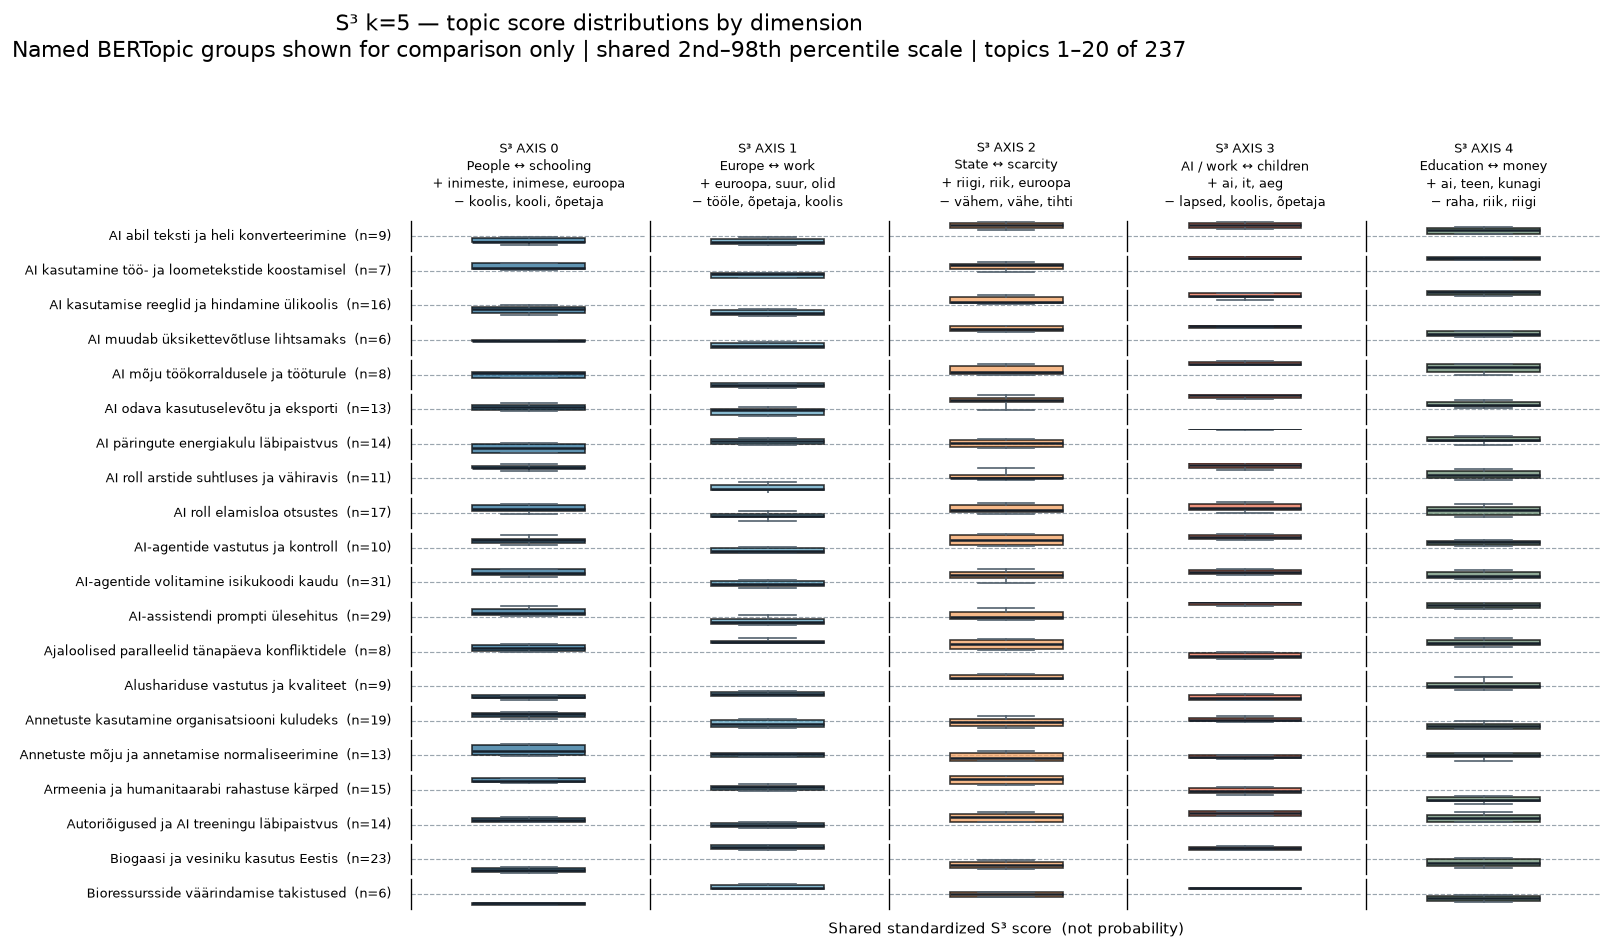

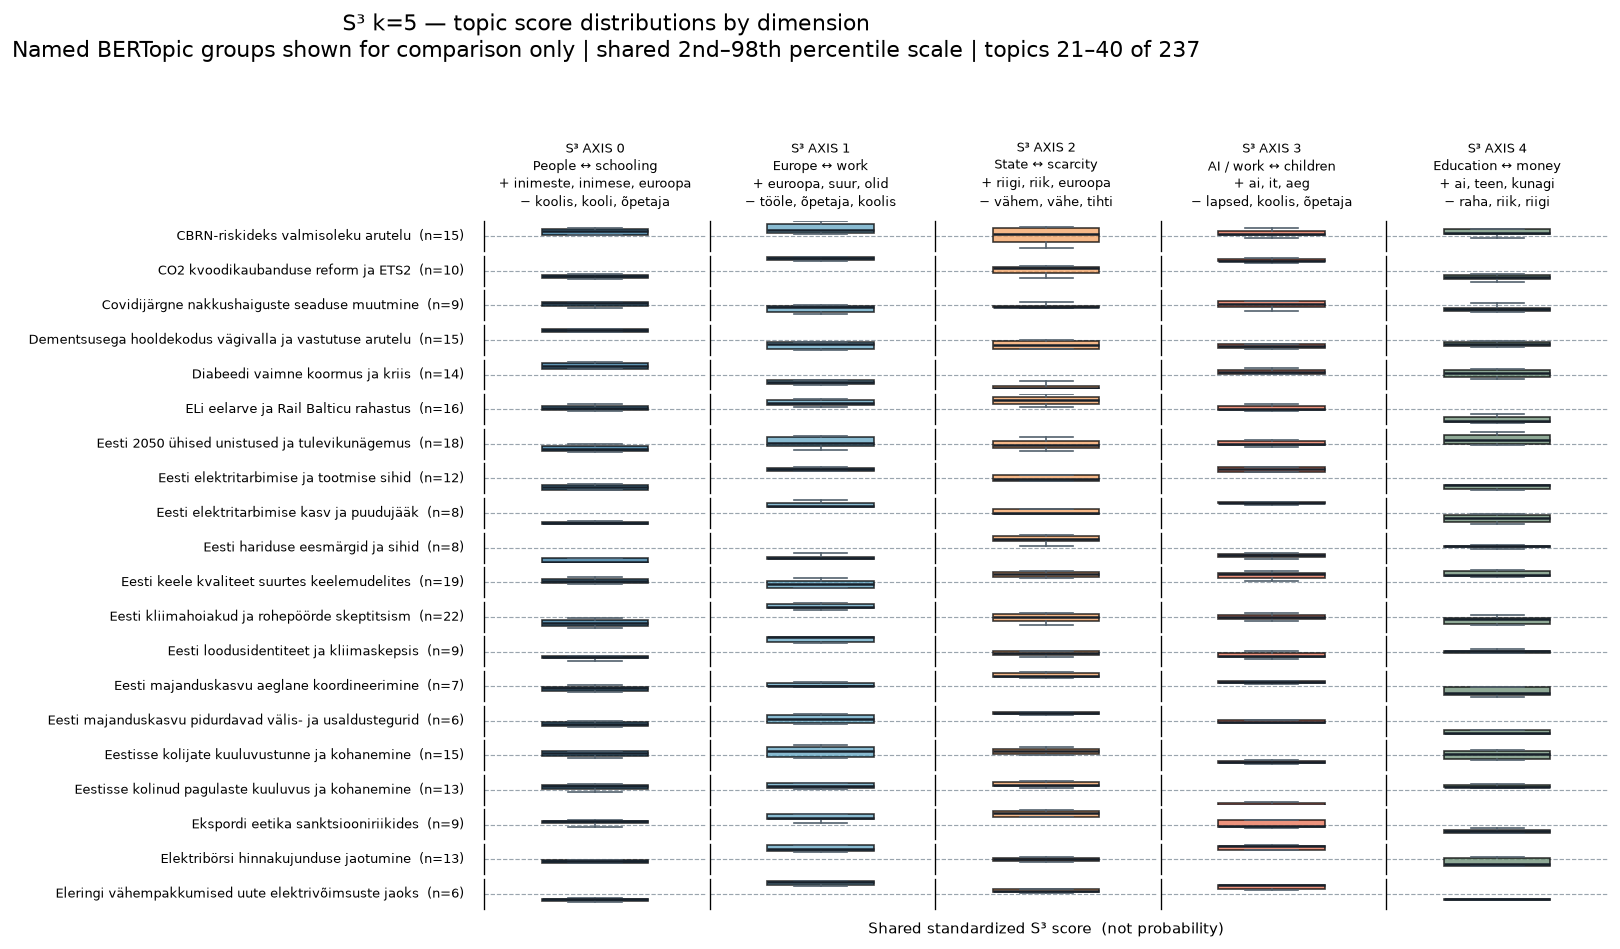

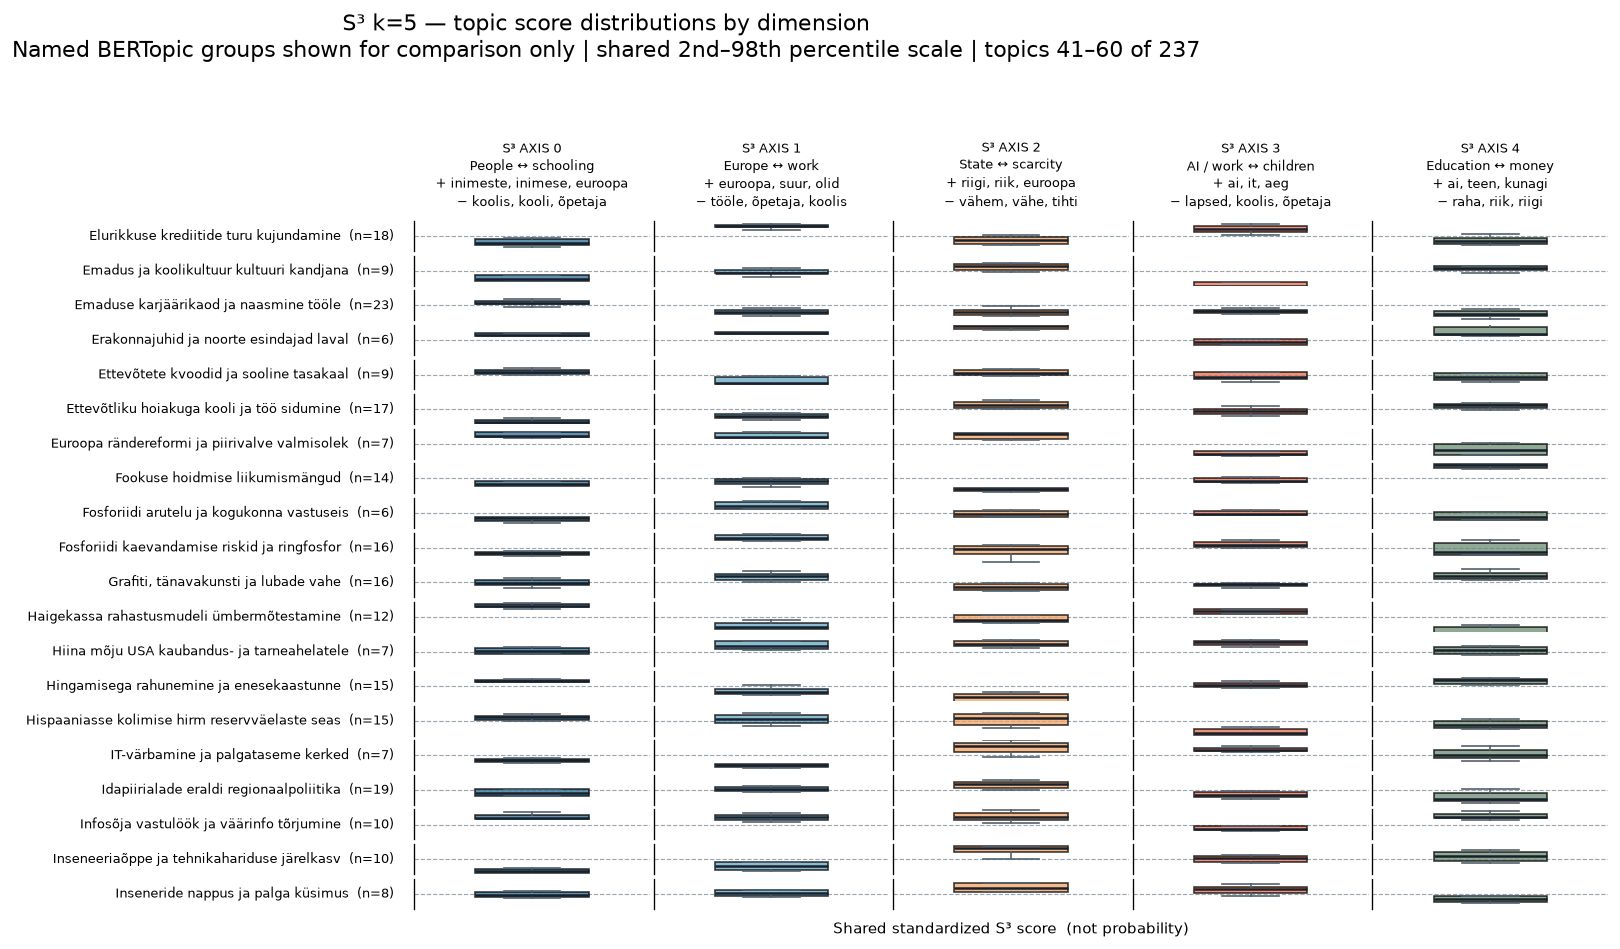

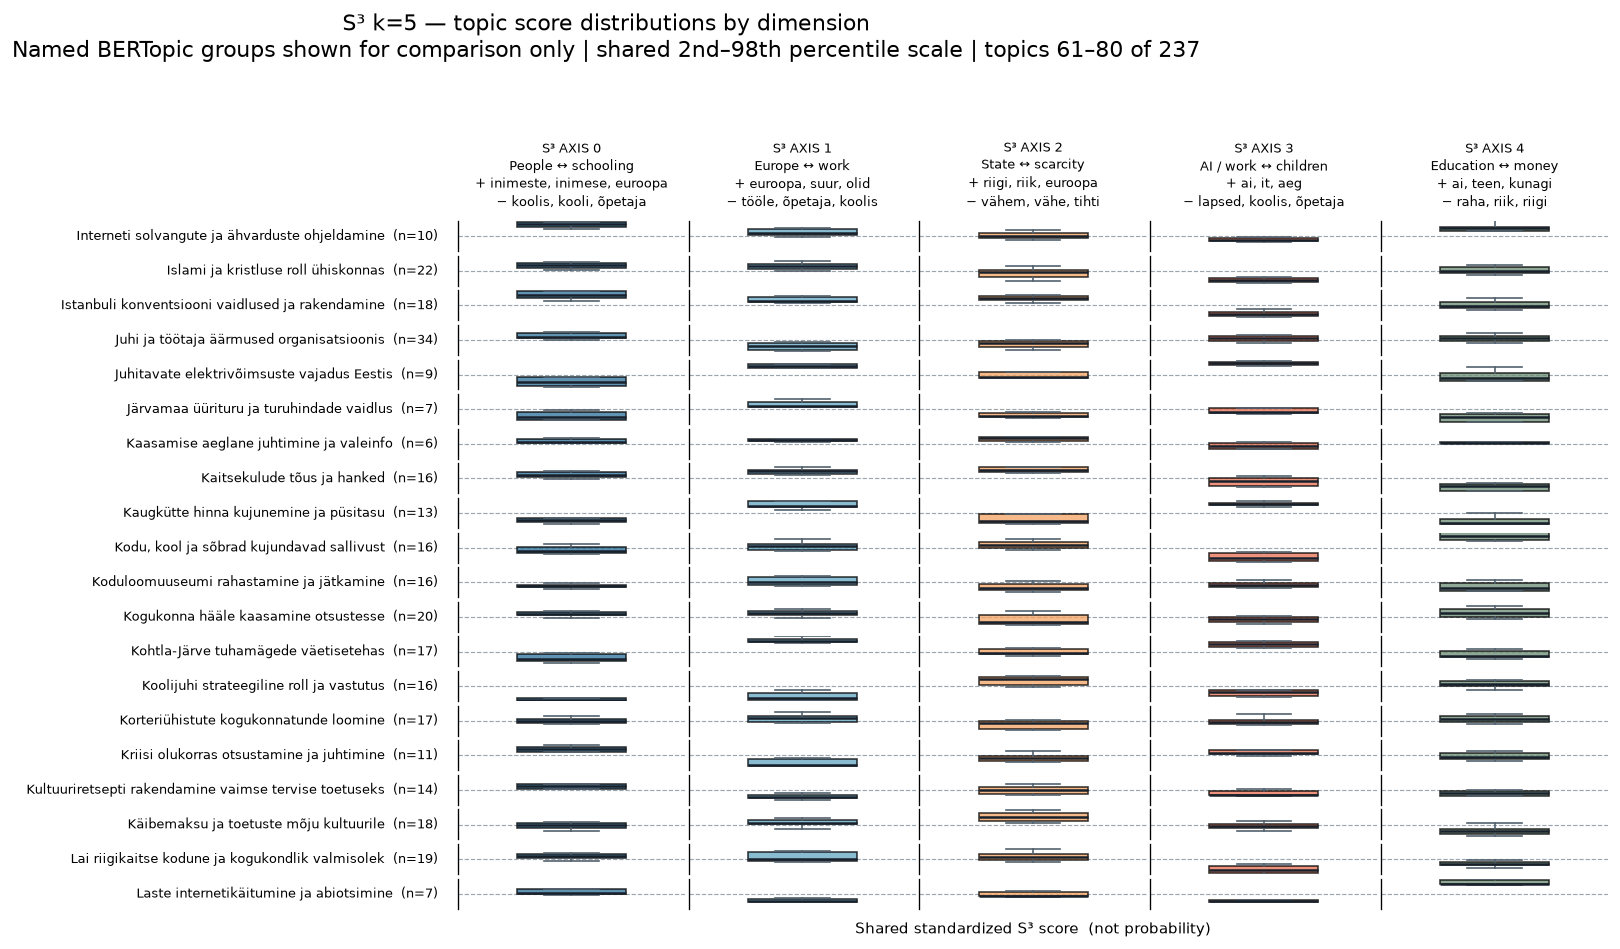

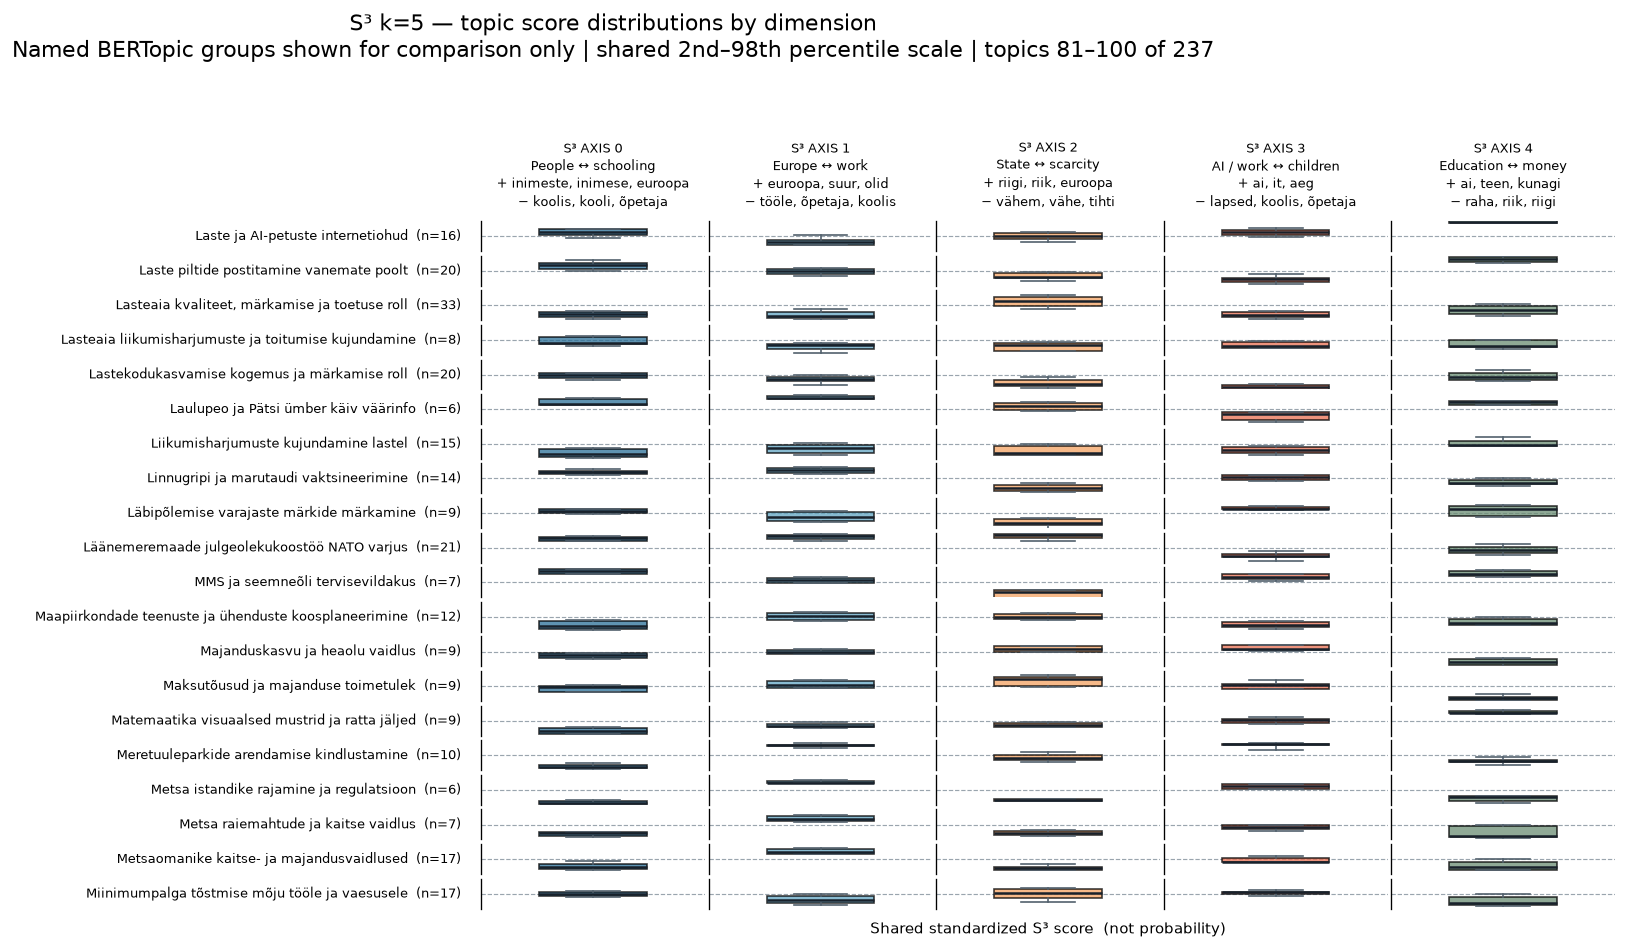

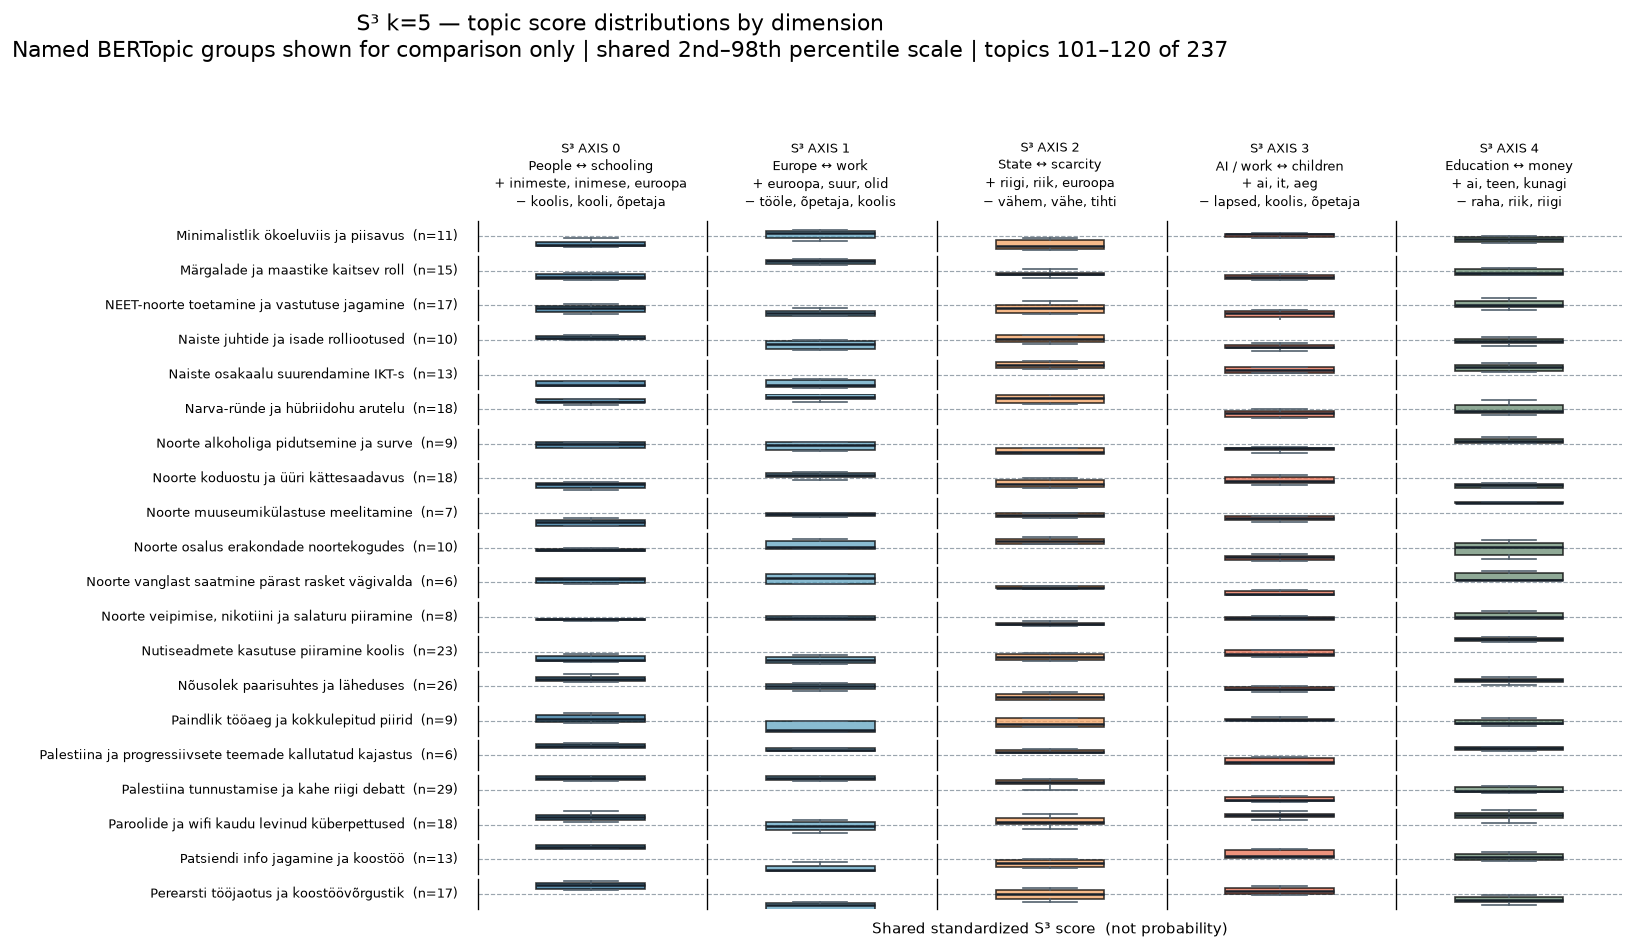

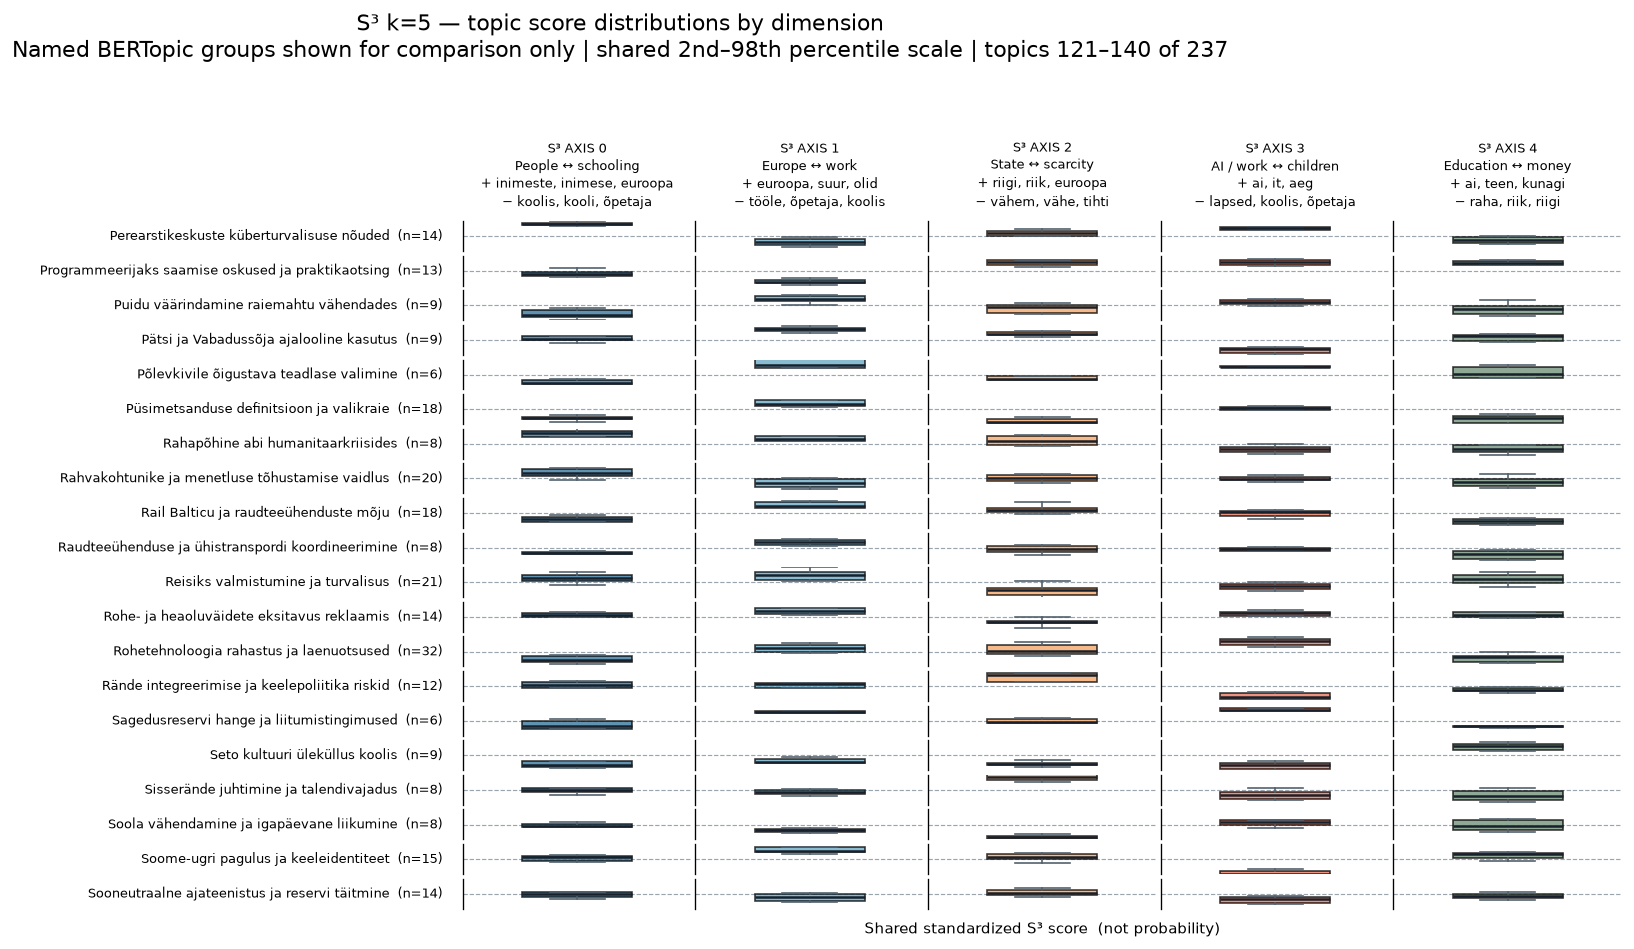

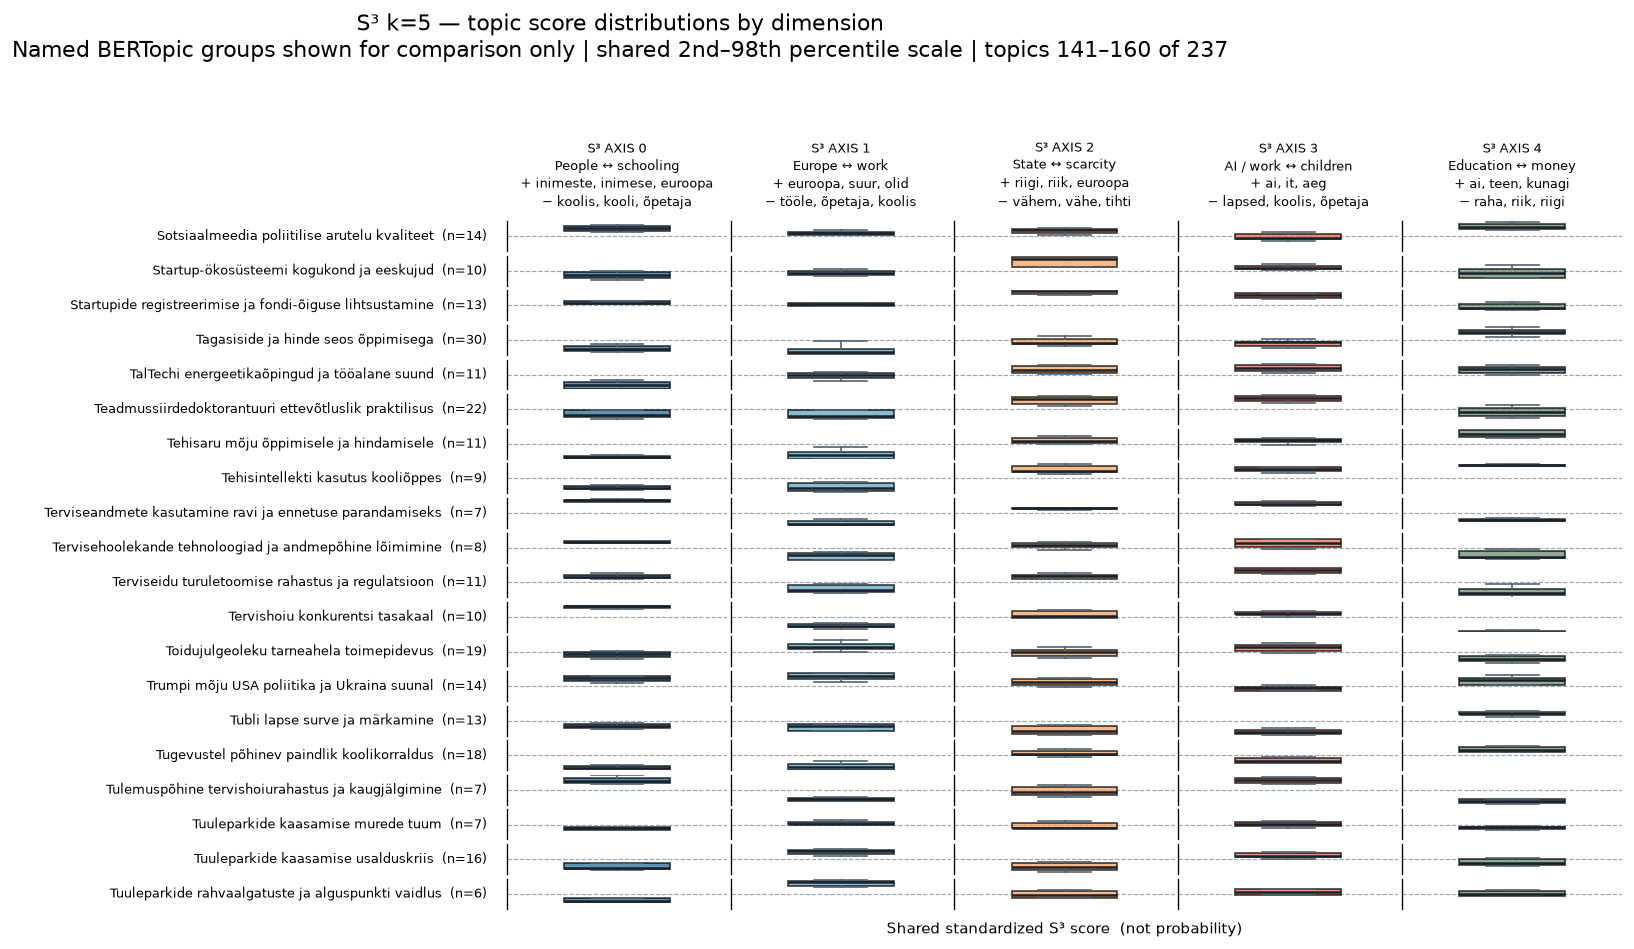

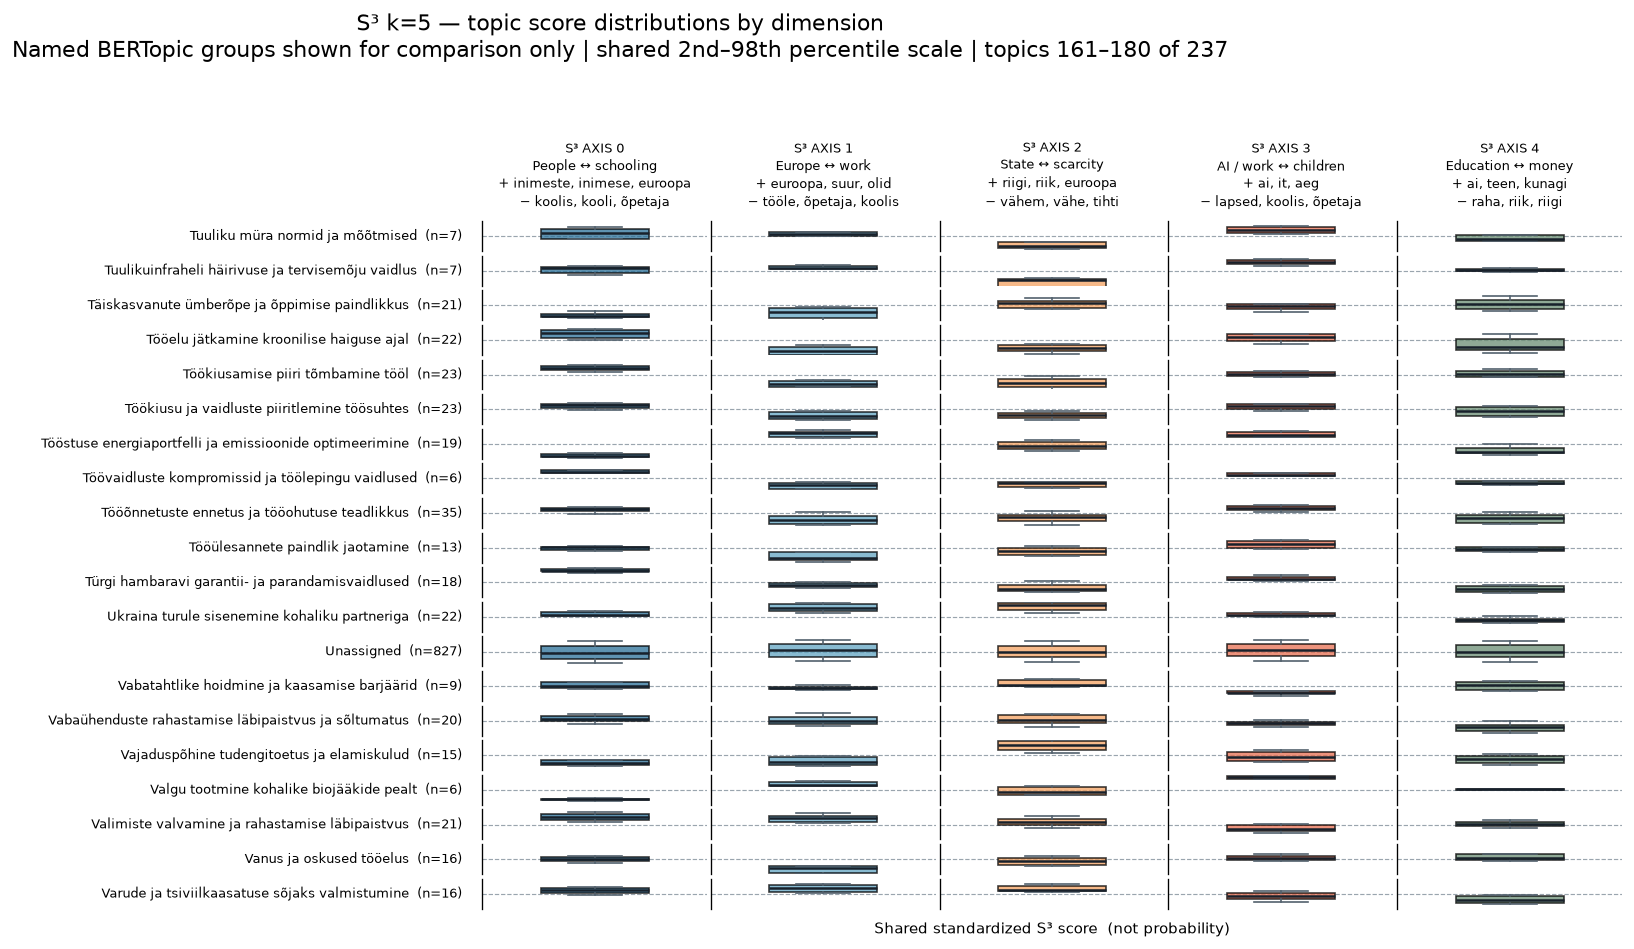

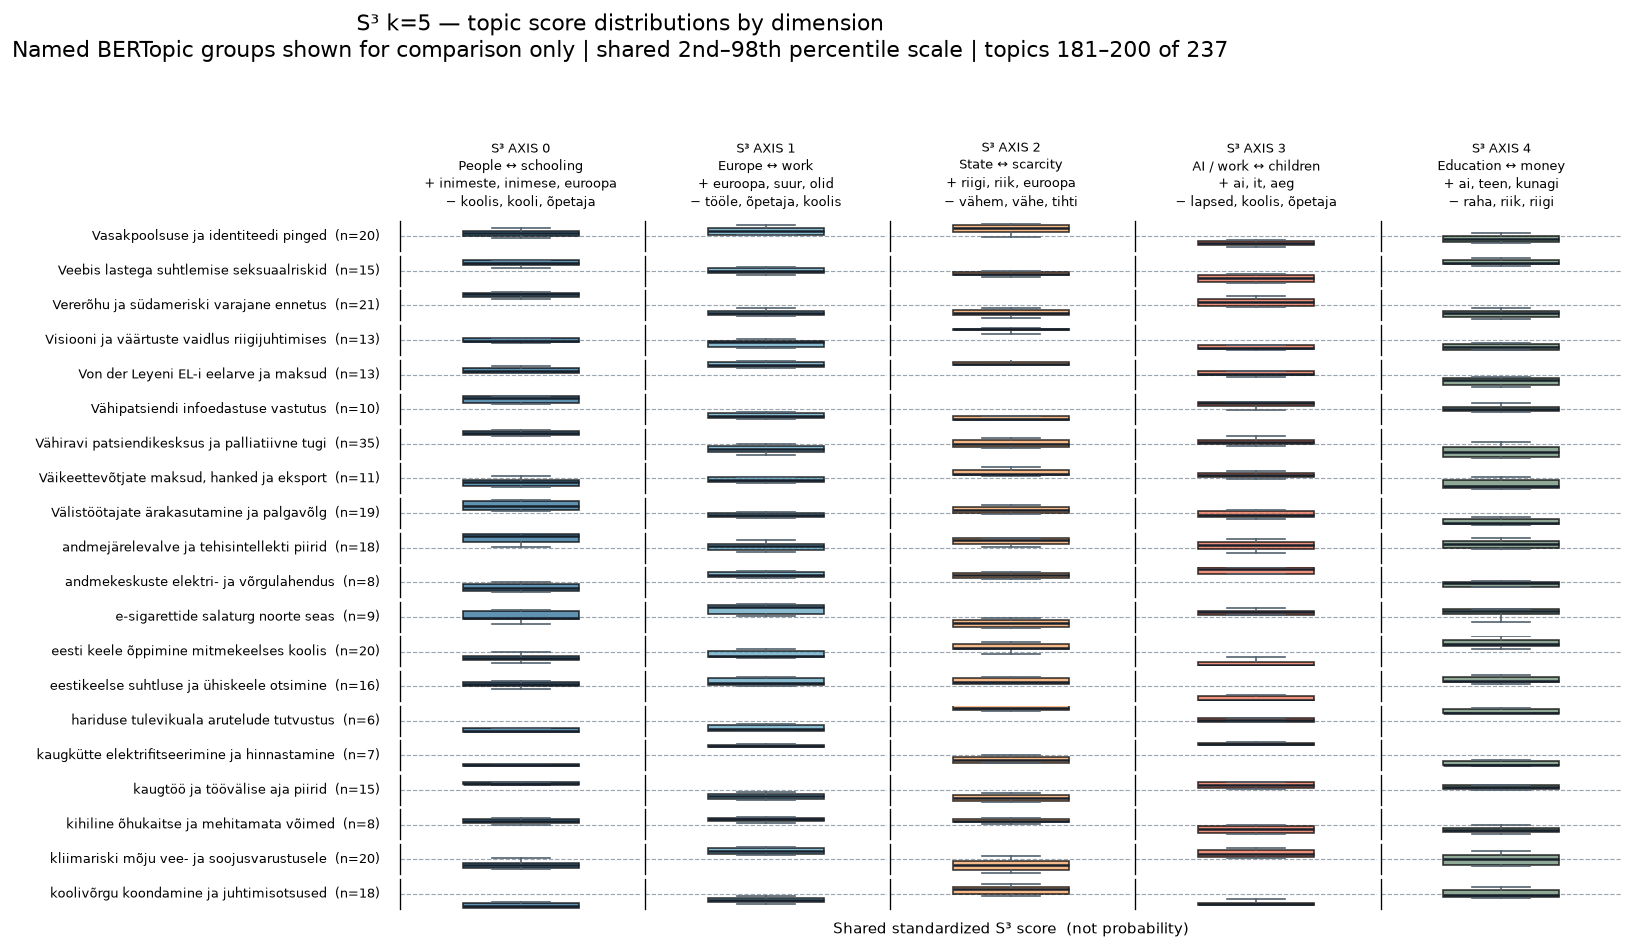

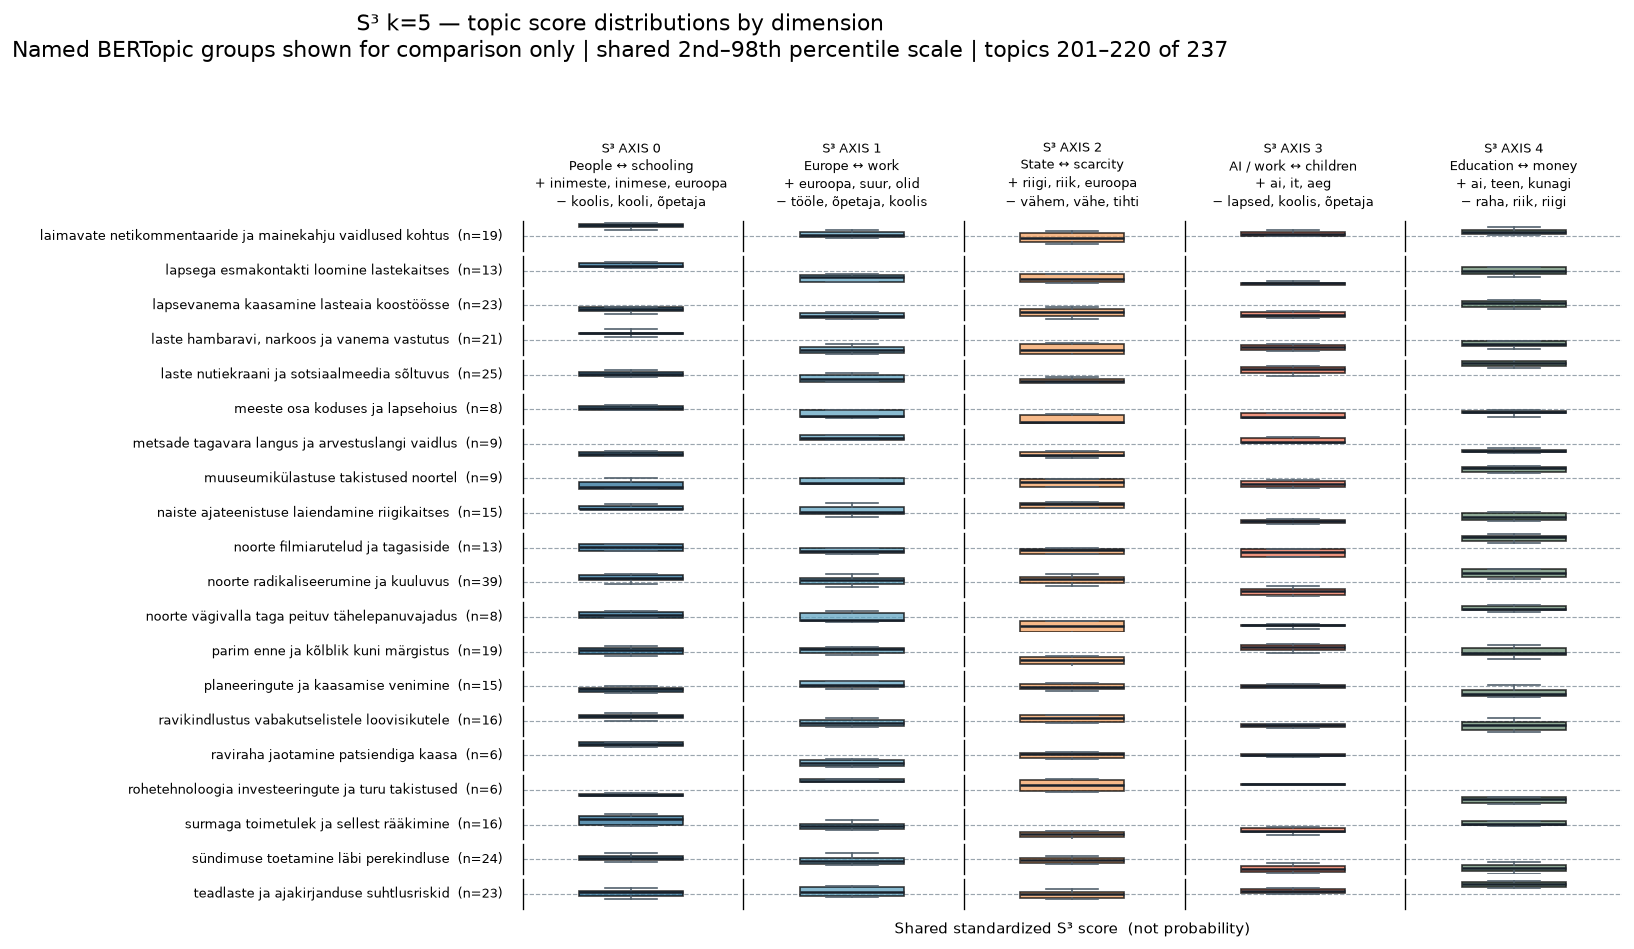

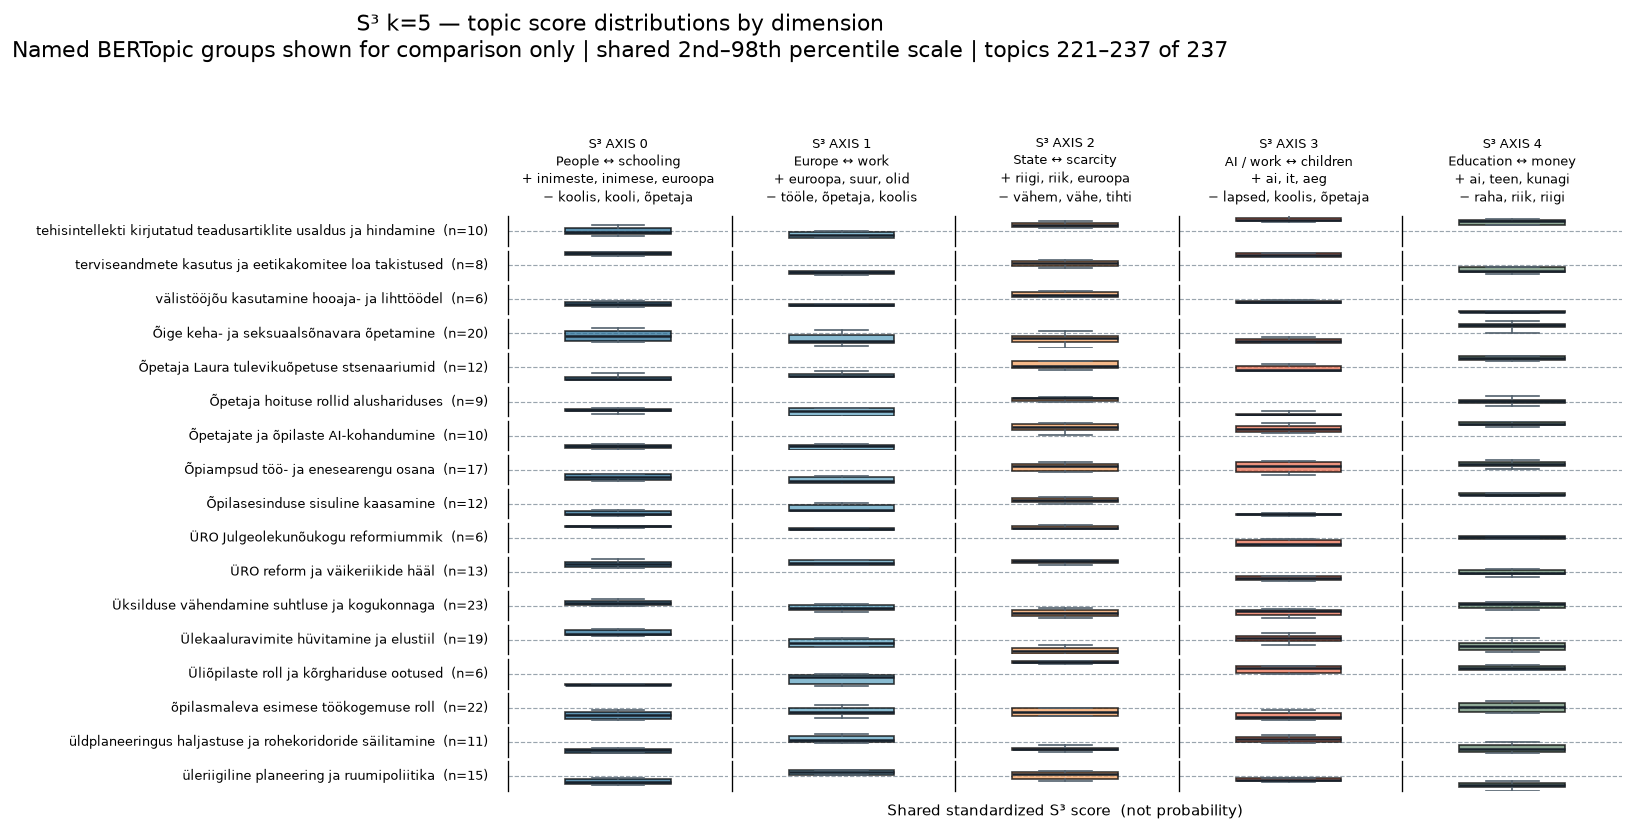

In [1]:
import sys
sys.path.insert(0, str(project_root))
import matplotlib.pyplot as plt
from IPython.display import Image
from scripts.s3_topic_axis import summarize_topic_axis_scores, build_topic_axis_review_tables, classify_topic_axis_percentiles

assert passages.topic_name.notna().all(), 'Every original BERTopic group must have a descriptive name.'
topic_names = passages.drop_duplicates('topic_id').set_index('topic_id').topic_name.to_dict()
topic_axis_summary = summarize_topic_axis_scores(passages, score_z)
topic_extremes, axis_keywords = build_topic_axis_review_tables(topic_axis_summary, topic_names, positive_terms, negative_terms)
axis_output_dir = results / 'jev-semantic-all' / 's3-topic-axis-distributions'
axis_output_dir.mkdir(parents=True, exist_ok=True)
run_tag = f'k{N_COMPONENTS}-seed{RANDOM_STATE}'
passage_score_path = axis_output_dir / f'passage-scores-{run_tag}.parquet'
topic_summary_path = axis_output_dir / f'topic-axis-summary-{run_tag}.parquet'
topic_extremes_path = axis_output_dir / f'topic-axis-extremes-{run_tag}.csv'
axis_keywords_path = axis_output_dir / f'axis-keywords-{run_tag}.csv'
scored_passages.to_parquet(passage_score_path, index=False)
topic_axis_summary.to_parquet(topic_summary_path, index=False)
topic_extremes.to_csv(topic_extremes_path, index=False)
axis_names = ['People ↔ schooling', 'Europe ↔ work', 'State ↔ scarcity', 'AI / work ↔ children', 'Education ↔ money']
axis_keywords['dimension_name'] = axis_names
topic_axis_percentiles = classify_topic_axis_percentiles(topic_axis_summary, lower_threshold=0.30, upper_threshold=0.70)
topic_axis_percentiles['topic_name'] = topic_axis_percentiles.topic_id.map(topic_names)
topic_axis_percentiles['dimension_name'] = topic_axis_percentiles.axis_id.map(dict(enumerate(axis_names)))
high_dimensions = topic_axis_percentiles.query("status == 'high'").groupby('topic_id').dimension_name.agg(', '.join).rename('high_dimensions')
low_dimensions = topic_axis_percentiles.query("status == 'low'").groupby('topic_id').dimension_name.agg(', '.join).rename('low_dimensions')
topic_extremes = topic_extremes.merge(high_dimensions, on='topic_id', how='left').merge(low_dimensions, on='topic_id', how='left')
topic_extremes[['high_dimensions', 'low_dimensions']] = topic_extremes[['high_dimensions', 'low_dimensions']].fillna('—')
axis_keywords.to_csv(axis_keywords_path, index=False)
percentiles_path = axis_output_dir / f'topic-axis-percentiles-{run_tag}.csv'
topic_axis_percentiles.to_csv(percentiles_path, index=False)
topic_extremes['highest_dimension'] = topic_extremes.highest_axis_id.map(lambda i: axis_names[i])
topic_extremes['lowest_dimension'] = topic_extremes.lowest_axis_id.map(lambda i: axis_names[i])
topic_extremes.to_csv(topic_extremes_path, index=False)
topic_axis_summary.to_parquet(topic_summary_path, index=False)
print('High = above the 70th percentile; Low = below the 30th percentile among topic groups, ranked separately for each axis. Exact boundaries and the middle 40% are Typical. These are relative comparisons, not probabilities.')
display(axis_keywords[['axis_id', 'dimension_name', 'positive_end_keywords', 'negative_end_keywords']])
visible = ['topic_name', 'passage_count', 'high_dimensions', 'low_dimensions', 'highest_dimension', 'highest_mean_z', 'highest_axis_positive_keywords', 'lowest_dimension', 'lowest_mean_z', 'lowest_axis_negative_keywords'] + [f'axis_{i}_mean_z' for i in range(N_COMPONENTS)]
display(topic_extremes[visible].sort_values('topic_name').reset_index(drop=True))

topics_per_page = 20
topic_order = topic_extremes.sort_values('topic_name').topic_id.tolist()
plot_dir = axis_output_dir / 'static-plots-k5-seed42'
plot_dir.mkdir(parents=True, exist_ok=True)
plot_low, plot_high = np.nanpercentile(score_z.to_numpy(), [2, 98])
axis_colors = ['#2A6F97', '#61A5C2', '#F4A261', '#E76F51', '#6A8D73']
for page_start in range(0, len(topic_order), topics_per_page):
    page_ids = topic_order[page_start:page_start + topics_per_page]
    fig, axes = plt.subplots(len(page_ids), N_COMPONENTS, figsize=(17, max(7, .40 * len(page_ids))), sharey=True, squeeze=False)
    for col, ax in enumerate(axes[0]):
        row = axis_keywords.iloc[col]
        ax.set_title(f"S³ AXIS {col}\n{row.dimension_name}\n+ {', '.join(row.positive_end_keywords.split(', ')[:3])}\n− {', '.join(row.negative_end_keywords.split(', ')[:3])}", fontsize=8, loc='center', pad=9, linespacing=1.35)
    for row_idx, topic_id in enumerate(page_ids):
        mask = scored_passages.topic_id.to_numpy() == topic_id
        for col, ax in enumerate(axes[row_idx]):
            values = score_z.loc[mask, score_columns[col]].to_numpy()
            artist = ax.boxplot(values, positions=[1], widths=.48, patch_artist=True, showfliers=False, whis=(10, 90), medianprops={'color':'#18212B','linewidth':1.5}, whiskerprops={'color':'#53616D'}, capprops={'color':'#53616D'})
            artist['boxes'][0].set_facecolor(axis_colors[col]); artist['boxes'][0].set_alpha(.75)
            ax.axhline(0, color='#9AA5AE', linewidth=.7, linestyle='--', zorder=0)
            ax.set_ylim(plot_low, plot_high); ax.set_xlim(.5, 1.5); ax.set_xticks([])
            ax.grid(axis='y', color='#E6EAED', linewidth=.6); ax.spines[['top','right','bottom']].set_visible(False)
            ax.set_yticks([])
            if col == 0:
                ax.set_ylabel(f"{topic_names[topic_id]}  (n={int(mask.sum())})", rotation=0, ha='right', va='center', labelpad=12, fontsize=8)
            else:
                ax.tick_params(axis='y', labelleft=False)
    axes[-1, 2].set_xlabel('Shared standardized S³ score  (not probability)', fontsize=9, labelpad=8)
    fig.suptitle(f"S³ k=5 — topic score distributions by dimension\nNamed BERTopic groups shown for comparison only | shared 2nd–98th percentile scale | topics {page_start+1}–{page_start+len(page_ids)} of {len(topic_order)}", fontsize=13, y=.995)
    fig.tight_layout(rect=[.2, .01, 1, .955], h_pad=.28, w_pad=.22)
    image_path = plot_dir / f'topic-axis-boxplots-page-{page_start//topics_per_page+1:02d}.png'
    fig.savefig(image_path, dpi=120, bbox_inches='tight', facecolor='white')
    plt.close(fig)
    display(Image(filename=str(image_path)))
print(f'Saved static topic comparison plots and named dimension tables under {axis_output_dir}')